In [1]:
from pathlib import Path
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window
import matplotlib.pyplot as plt

spark = (
    SparkSession.builder
    .appName("RetailIntelligence-TP4-Visualisations")
    .master("local[*]").config("spark.hadoop.fs.defaultFS", "file:///")
    .getOrCreate()
)

# Chemins vers les données TP3 : lecture seule
TP3_DATA = Path.home() / "retail-intelligence" / "tp3" / "data"

sales_by_store_date_path = (
    TP3_DATA / "silver-transformed" / "sales_by_store_date"
)

store_sales_path = TP3_DATA / "silver" / "store_sales"

# Enregistrement du graphique
output_dir = Path.home() / "retail-intelligence" / "tp4" / "visualisations"
output_dir.mkdir(parents=True, exist_ok=True)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/21 10:55:44 WARN Utils: Your hostname, NAVID-DELL, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/11/21 10:55:44 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/home/navid/retail-intelligence/tp4/retail_intel_tp4_venv/lib/python3.12/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/11/21 10:55:45 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


/home/navid/retail-intelligence/tp4/retail_intel_tp4_venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/navid/retail-intelligence/tp4/retail_intel_tp4_venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
                                                                                

,Rang,Identifiant magasin,CA TTC,Part du CA global
0,1,7,103 384 198.80,8.60 %
1,2,4,101 130 648.13,8.41 %
2,3,9,101 109 360.86,8.41 %
3,4,0,101 047 840.24,8.41 %
4,5,8,100 916 146.68,8.39 %
5,6,3,100 377 573.32,8.35 %
6,7,1,100 230 588.43,8.34 %
7,8,11,99 910 528.38,8.31 %
8,9,6,99 040 970.11,8.24 %
9,10,10,98 490 674.24,8.19 %


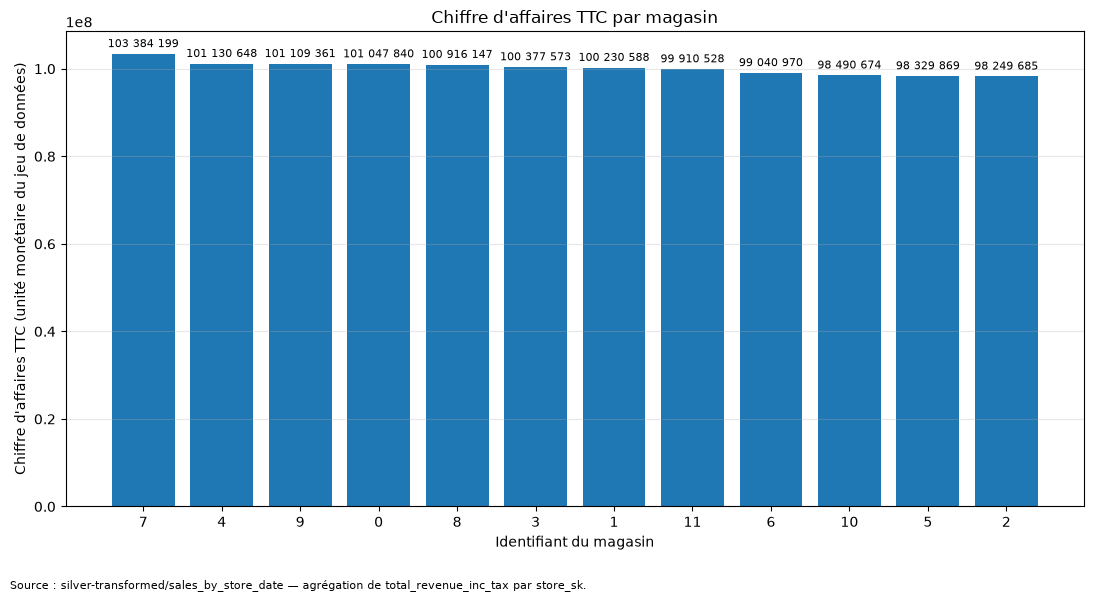

In [2]:
# Lecture des données
df_sales_store_date = spark.read.parquet(
    str(sales_by_store_date_path)
)

# Agrégation du chiffre d'affaires par magasin
df_revenue_store = (
    df_sales_store_date
    .groupBy("store_sk")
    .agg(
        F.sum("total_revenue_inc_tax").alias("ca_ttc")
    )
    .orderBy(F.desc("ca_ttc"))
)

# Conversion en Pandas : seulement 12 lignes
pdf_revenue_store = df_revenue_store.toPandas()


# Tableau de synthèse du chiffre d'affaires par magasin
pdf_revenue_summary = pdf_revenue_store.copy()

# Calcul de la part de chaque magasin dans le CA global
ca_global = pdf_revenue_summary["ca_ttc"].sum()

pdf_revenue_summary["part_ca_pct"] = (
    pdf_revenue_summary["ca_ttc"] / ca_global * 100
)

# Classement des magasins
pdf_revenue_summary.insert(
    0,
    "rang_ca",
    range(1, len(pdf_revenue_summary) + 1)
)

# Formatage des valeurs pour l'affichage
pdf_revenue_summary["ca_ttc"] = (
    pdf_revenue_summary["ca_ttc"].map(
        lambda value: f"{value:,.2f}".replace(",", " ")
    )
)

pdf_revenue_summary["part_ca_pct"] = (
    pdf_revenue_summary["part_ca_pct"].map(
        lambda value: f"{value:.2f} %"
    )
)

pdf_revenue_summary = pdf_revenue_summary.rename(
    columns={
        "rang_ca": "Rang",
        "store_sk": "Identifiant magasin",
        "ca_ttc": "CA TTC",
        "part_ca_pct": "Part du CA global"
    }
)

display(pdf_revenue_summary)

# Export du tableau
pdf_revenue_summary.to_csv(
    output_dir / "synthese_ca_par_magasin.csv",
    index=False,
    encoding="utf-8-sig"
)


# Création du graphique
fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    pdf_revenue_store["store_sk"].astype(str),
    pdf_revenue_store["ca_ttc"].astype(float)
)

ax.set_title("Chiffre d'affaires TTC par magasin")
ax.set_xlabel("Identifiant du magasin")
ax.set_ylabel("Chiffre d'affaires TTC (unité monétaire du jeu de données)")
ax.grid(axis="y", alpha=0.3)

# Affichage des valeurs au-dessus des barres
ax.bar_label(
    bars,
    labels=[
        f"{value:,.0f}".replace(",", " ")
        for value in pdf_revenue_store["ca_ttc"].astype(float)
    ],
    padding=3,
    fontsize=8
)

fig.text(
    0.01, 0.01,
    "Source : silver-transformed/sales_by_store_date — "
    "agrégation de total_revenue_inc_tax par store_sk.",
    fontsize=8
)

plt.tight_layout(rect=[0, 0.05, 1, 1])

fig.savefig(
    output_dir / "ca_ttc_par_magasin.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

/home/navid/retail-intelligence/tp4/retail_intel_tp4_venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/navid/retail-intelligence/tp4/retail_intel_tp4_venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


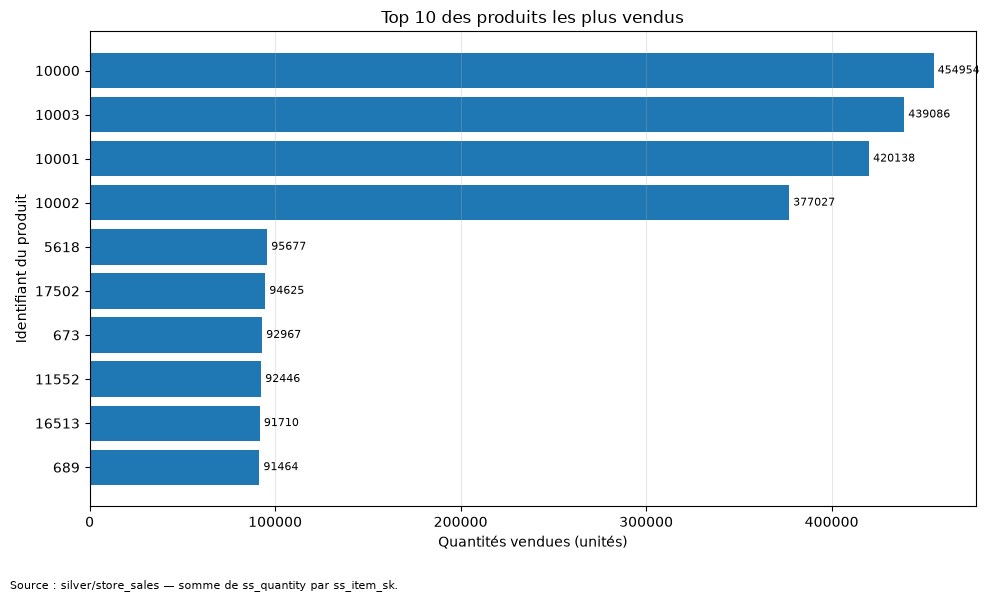

In [3]:
# Lecture des ventes détaillées
df_store_sales = spark.read.parquet(str(store_sales_path))

# Agrégation des quantités vendues par produit
df_product_sales = (
    df_store_sales
    .groupBy("ss_item_sk")
    .agg(
        F.sum("ss_quantity").alias("quantites_vendues")
    )
    .orderBy(F.desc("quantites_vendues"))
)

# Sélection des 10 produits les plus vendus
df_top10_products = df_product_sales.limit(10)

# Conversion en Pandas
pdf_top10_products = df_top10_products.toPandas()

# Graphique
fig, ax = plt.subplots(figsize=(10, 6))

# Inversion pour placer le produit le plus vendu en haut
pdf_top10_products = pdf_top10_products.sort_values(
    "quantites_vendues",
    ascending=True
)

bars = ax.barh(
    pdf_top10_products["ss_item_sk"].astype(str),
    pdf_top10_products["quantites_vendues"]
)

ax.set_title("Top 10 des produits les plus vendus")
ax.set_xlabel("Quantités vendues (unités)")
ax.set_ylabel("Identifiant du produit")
ax.grid(axis="x", alpha=0.3)

ax.bar_label(bars, padding=3, fontsize=8)

fig.text(
    0.01, 0.01,
    "Source : silver/store_sales — somme de ss_quantity "
    "par ss_item_sk.",
    fontsize=8
)

plt.tight_layout(rect=[0, 0.05, 1, 1])

# Enregistrement
fig.savefig(
    output_dir / "top10_produits_quantites.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [4]:
spark.stop()
print("Session Spark fermée.")

Session Spark fermée.
